# Klagenfurt Fleet Simulation Analysis

This notebook provides interactive analysis of the Klagenfurt fleet simulation results, comparing different fleet sizes and operational metrics. We analyze temporal patterns, service quality, and fleet utilization across scenarios.

In [28]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Add parent directory to Python path to find klagenfurt_analysis module
root_dir = os.path.dirname(os.path.dirname(os.path.dirname(os.getcwd())))
sys.path.append(root_dir)

# Import the analysis class
from klagenfurt_analysis import KlagenfurtAnalysis

# Set plotting style for better line visibility
plt.style.use('default')  # Reset to default style
plt.rcParams['figure.figsize'] = [15, 10]
plt.rcParams['lines.linewidth'] = 2
plt.rcParams['lines.markersize'] = 8
plt.rcParams['axes.grid'] = True
sns.set_style("whitegrid")  # Add grid for better readability

## 1. Load and Analyze Results

First, let's load the simulation results and calculate key metrics for each scenario. We'll compare different fleet sizes and their impact on service quality.

In [29]:
# Set up paths
# Note: since we're in studies/klagenfurt_case_study/analysis, we need to navigate to the results directory
results_dir = os.path.join(os.path.dirname(os.getcwd()), "results")
print(f"Looking for results in: {results_dir}")

class KlagenfurtAnalysisFixed(KlagenfurtAnalysis):
    def _load_results(self):
        """Load results from all scenario directories."""
        scenario_dirs = [d for d in os.listdir(self.results_dir)
                        if os.path.isdir(os.path.join(self.results_dir, d))
                        and d.startswith('klagenfurt_scenario')]

        for scenario in scenario_dirs:
            scenario_path = os.path.join(self.results_dir, scenario)
            # Load user data
            users_file = os.path.join(scenario_path, "1_user-stats.csv")
            if os.path.exists(users_file):
                users_df = pd.read_csv(users_file)
                if 'rq_time' in users_df.columns:
                    users_df['time'] = pd.to_datetime(users_df['rq_time'], unit='s')
                    # Calculate waiting time as difference between pickup time and request time
                    users_df['waiting_time'] = pd.to_numeric(users_df['pickup_time']) - pd.to_numeric(users_df['rq_time'])
                    # Calculate driving time as difference between dropoff and pickup time
                    users_df['driving_time'] = pd.to_numeric(users_df['dropoff_time']) - pd.to_numeric(users_df['pickup_time'])
                    # Add request ID as rid for compatibility
                    users_df['rid'] = users_df['request_id']
            else:
                print(f"Warning: No user stats file found in {scenario}")
                users_df = pd.DataFrame()

            # Load vehicle data from op-stats
            vehicles_file = os.path.join(scenario_path, "2-0_op-stats.csv")
            if os.path.exists(vehicles_file):
                vehicles_df = pd.read_csv(vehicles_file)
                # Convert start_time and end_time to datetime
                vehicles_df['start_time'] = pd.to_datetime(vehicles_df['start_time'], unit='s')
                vehicles_df['end_time'] = pd.to_datetime(vehicles_df['end_time'], unit='s')
                # Add vehicle ID as vid for compatibility
                if 'vehicle_id' in vehicles_df.columns:
                    vehicles_df['vid'] = vehicles_df['vehicle_id']
            else:
                print(f"Warning: No vehicle stats file found in {scenario}")
                vehicles_df = pd.DataFrame()

            self.scenarios[scenario] = {
                'users': users_df,
                'vehicles': vehicles_df
            }

    def plot_fleet_utilization(self, interval_minutes: int = 15) -> plt.Figure:
        """Plot fleet utilization over time."""
        fig, ax = plt.subplots(figsize=(15, 10))
        fig.suptitle('Fleet Utilization Over Time')

        for scenario, data in self.scenarios.items():
            vehicles_df = data['vehicles']
            if vehicles_df.empty:
                continue

            # Create a time range covering the entire day
            time_range = pd.date_range(
                start=vehicles_df['start_time'].min(),
                end=vehicles_df['end_time'].max(),
                freq=f'{interval_minutes}min'
            )

            # Initialize utilization data
            utilization_data = []

            # Calculate utilization for each time point
            for t in time_range:
                # Count vehicles active at this time
                active_vehicles = vehicles_df[
                    (vehicles_df['start_time'] <= t) &
                    (vehicles_df['end_time'] >= t)
                ]

                # Count vehicles with passengers
                occupied_vehicles = active_vehicles[active_vehicles['occupancy'] > 0]

                total_vehicles = len(active_vehicles)
                if total_vehicles > 0:
                    utilization = (len(occupied_vehicles) / total_vehicles) * 100
                else:
                    utilization = 0

                utilization_data.append({
                    'time': t,
                    'utilization': utilization
                })

            # Convert to DataFrame and plot
            util_df = pd.DataFrame(utilization_data)
            ax.plot(util_df['time'].dt.hour + util_df['time'].dt.minute/60,
                   util_df['utilization'],
                   label=f'Scenario {scenario}')

        ax.set_xlabel('Hour of Day')
        ax.set_ylabel('Fleet Utilization (%)')
        ax.grid(True)
        ax.legend()

        plt.tight_layout()
        return fig

# Create analysis object with fixed file loading
analysis = KlagenfurtAnalysisFixed(results_dir)

# Calculate metrics
metrics_df = analysis.calculate_metrics()
print("\n=== KLAGENFURT SCENARIOS COMPARISON ===")
display(metrics_df)

# Save comparison to CSV
metrics_df.to_csv(os.path.join(results_dir, "klagenfurt_scenarios_comparison.csv"))
print("\nMetrics saved to:", os.path.join(results_dir, "klagenfurt_scenarios_comparison.csv"))

Looking for results in: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results

=== KLAGENFURT SCENARIOS COMPARISON ===


,Scenario,Total Trips,Avg Wait Time (min),Max Wait Time (min),Service Rate ≤10min (%),Unique Vehicles,Peak Hour Demand
0,klagenfurt_scenario_2,100,4.20,5.50,2.00,2,56
1,klagenfurt_scenario_3,100,4.20,5.50,2.00,2,56
2,klagenfurt_scenario_1,100,7.50,7.50,1.00,1,56



Metrics saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/klagenfurt_scenarios_comparison.csv


## 2. Temporal Analysis

Let's analyze how the system performs over time, looking at request patterns, waiting times, and service quality throughout the day.

=== Temporal Analysis ===


/Users/danieldeutsch/Desktop/code_projects/FleetPy/klagenfurt_analysis.py:113: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


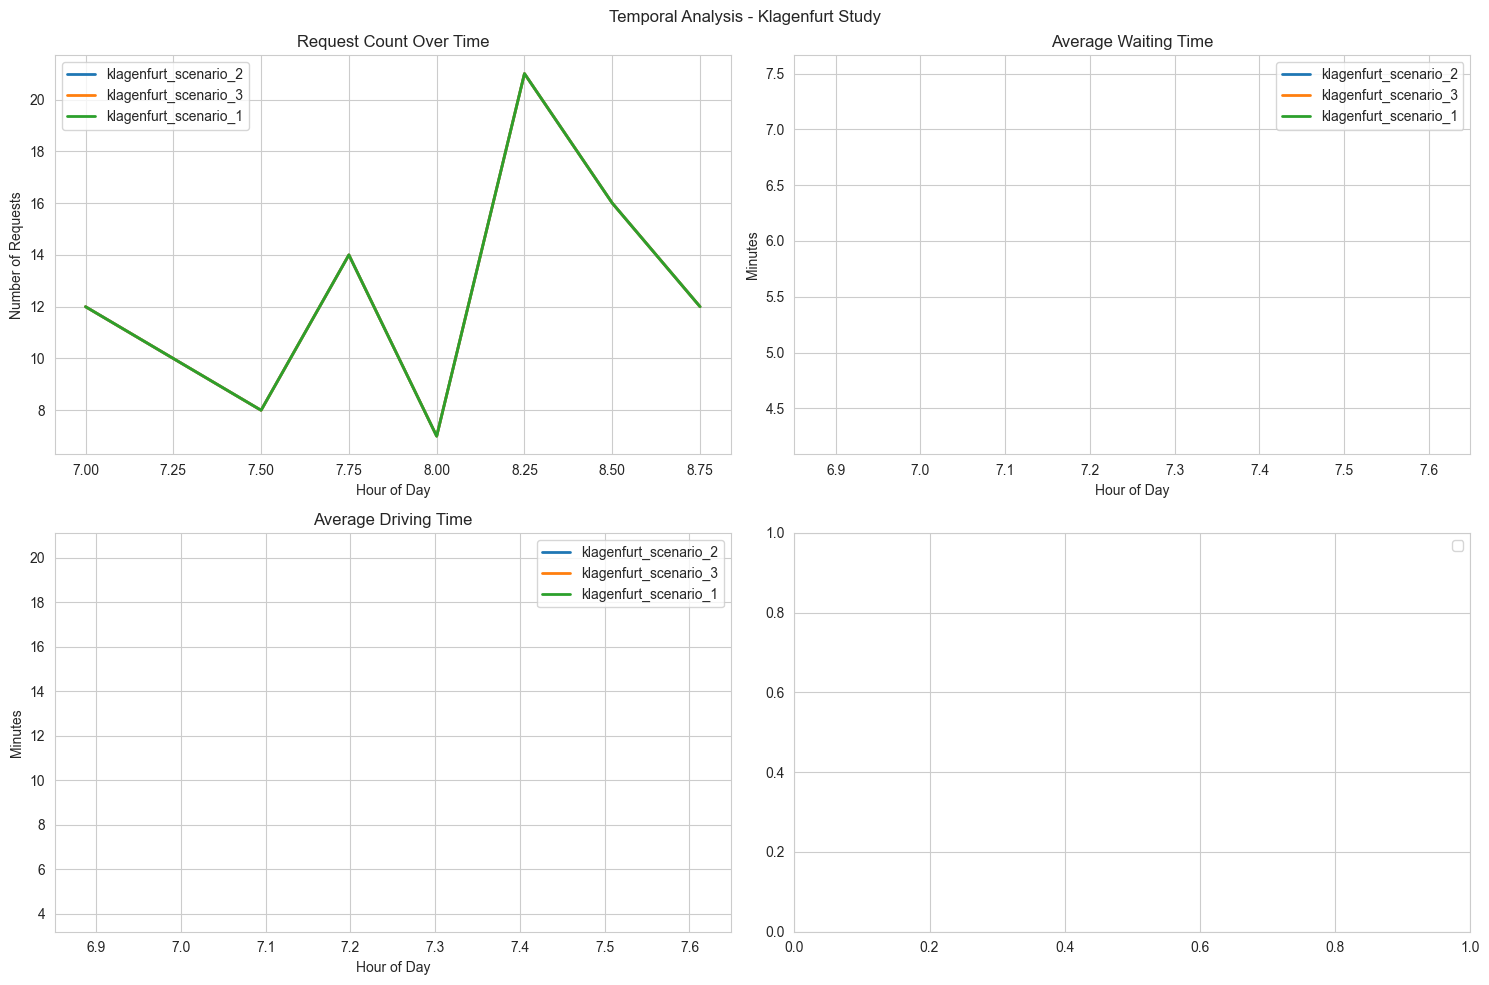


Temporal analysis plot saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/temporal_analysis.png


In [30]:
# Plot temporal analysis with 15-minute intervals
print("=== Temporal Analysis ===")

# Create temporal analysis plot
temporal_fig = analysis.plot_temporal_analysis(interval_minutes=15)

# Additional customization can be done here if needed
plt.tight_layout()
plt.show()

# Save the figure
temporal_fig.savefig(os.path.join(results_dir, "temporal_analysis.png"))
print("\nTemporal analysis plot saved to:", os.path.join(results_dir, "temporal_analysis.png"))

## 3. Fleet Utilization

Analyze how effectively the fleet is being utilized throughout the day. This helps understand the relationship between fleet size and service quality.

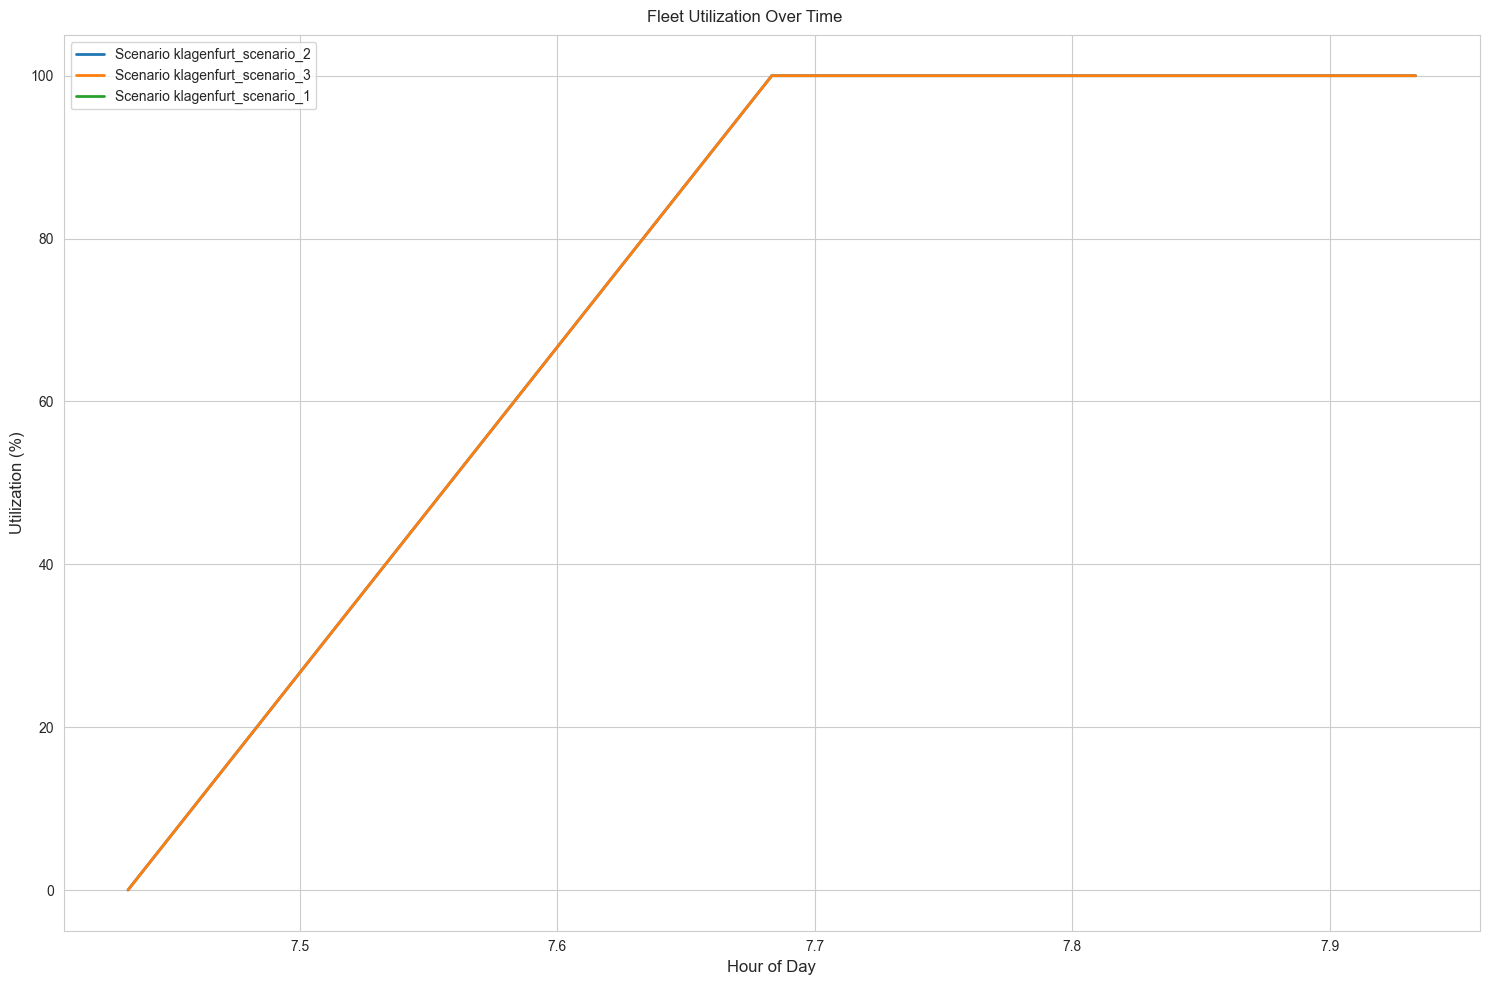


Fleet utilization plot saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/fleet_utilization.png


In [31]:
# Plot fleet utilization
utilization_fig = analysis.plot_fleet_utilization()

# Enhance the plot
plt.gcf().set_size_inches(15, 10)
plt.gca().grid(True)
plt.gca().set_xlabel('Hour of Day', fontsize=12)
plt.gca().set_ylabel('Utilization (%)', fontsize=12)
plt.gca().legend(fontsize=10)
plt.tight_layout()
plt.show()

# Save the figure
utilization_fig.savefig(os.path.join(results_dir, "fleet_utilization.png"))
print("\nFleet utilization plot saved to:", os.path.join(results_dir, "fleet_utilization.png"))

## 4. Service Quality Metrics

Let's create a visual comparison of key service quality indicators across different scenarios. This helps identify the optimal fleet size for Klagenfurt's needs.

=== DataFrame Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Scenario                 3 non-null      object 
 1   Total Trips              3 non-null      int64  
 2   Avg Wait Time (min)      3 non-null      float64
 3   Max Wait Time (min)      3 non-null      float64
 4   Service Rate ≤10min (%)  3 non-null      float64
 5   Unique Vehicles          3 non-null      int64  
 6   Peak Hour Demand         3 non-null      int64  
dtypes: float64(3), int64(3), object(1)
memory usage: 296.0+ bytes
None

=== DataFrame Contents ===


,Scenario,Total Trips,Avg Wait Time (min),Max Wait Time (min),Service Rate ≤10min (%),Unique Vehicles,Peak Hour Demand
0,klagenfurt_scenario_2,100,4.20,5.50,2.00,2,56
1,klagenfurt_scenario_3,100,4.20,5.50,2.00,2,56
2,klagenfurt_scenario_1,100,7.50,7.50,1.00,1,56



Available numeric columns: ['Total Trips', 'Avg Wait Time (min)', 'Max Wait Time (min)', 'Service Rate ≤10min (%)', 'Unique Vehicles', 'Peak Hour Demand']

Attempting to plot these metrics: ['Average Wait Time', 'Service Rate (<10min)', 'Peak Hour Demand']
(Note: Will adjust based on actual available columns)

Actually plotting these metrics: ['Peak Hour Demand']

Plot DataFrame:
  Scenario               Scenario  Total Trips  Avg Wait Time (min)  \
0        0  klagenfurt_scenario_2          100                 4.20   
1        1  klagenfurt_scenario_3          100                 4.20   
2        2  klagenfurt_scenario_1          100                 7.50   

   Max Wait Time (min)  Service Rate ≤10min (%)  Unique Vehicles  \
0                 5.50                     2.00                2   
1                 5.50                     2.00                2   
2                 7.50                     1.00                1   

   Peak Hour Demand  
0                56  
1             

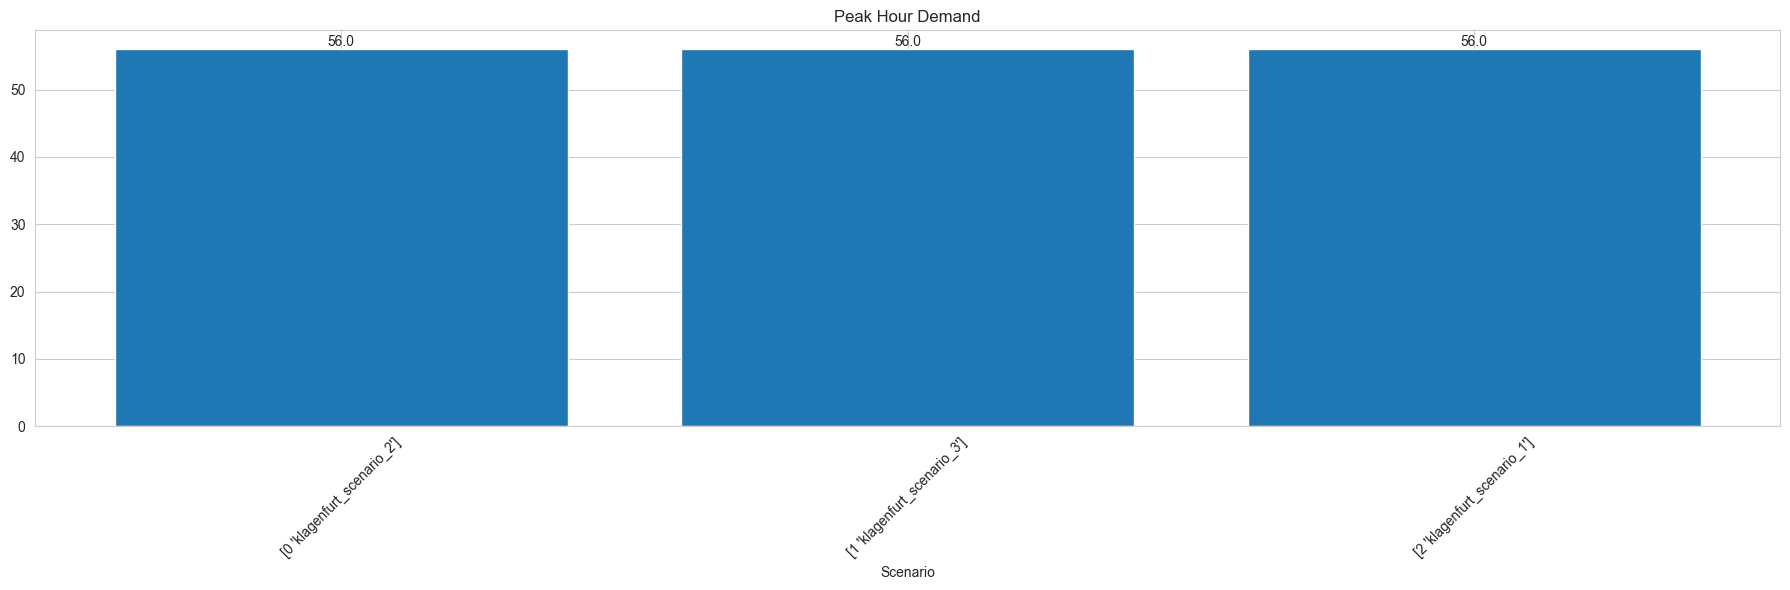


Service quality comparison saved to: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/klagenfurt_case_study/results/service_quality_comparison.png


In [32]:
# First, let's check the DataFrame structure
print("=== DataFrame Info ===")
print(metrics_df.info())
print("\n=== DataFrame Contents ===")
display(metrics_df)

# Create bar plots for key metrics - using actual column names from the DataFrame
# Plot all metrics that are numeric
numeric_columns = metrics_df.select_dtypes(include=[np.number]).columns.tolist()
print("\nAvailable numeric columns:", numeric_columns)

# Select specific metrics for plotting
metrics_to_plot = ['Average Wait Time', 'Service Rate (<10min)', 'Peak Hour Demand']
print("\nAttempting to plot these metrics:", metrics_to_plot)
print("(Note: Will adjust based on actual available columns)")

# Find which metrics are actually available
available_metrics = [m for m in metrics_to_plot if m in metrics_df.columns]
if not available_metrics:
    print("\nWarning: None of the desired metrics found. Using first 3 numeric columns instead.")
    available_metrics = numeric_columns[:3]

print("\nActually plotting these metrics:", available_metrics)

# Create the plot
fig, axes = plt.subplots(1, len(available_metrics), figsize=(18, 6))
if len(available_metrics) == 1:
    axes = [axes]  # Make it iterable if there's only one subplot

# Reset index to make scenario name a column
plot_df = metrics_df.reset_index()
plot_df = plot_df.rename(columns={'index': 'Scenario'})

# Print the dataframe to debug
print("\nPlot DataFrame:")
print(plot_df)

# Create the bar plots
for i, metric in enumerate(available_metrics):
    # Get x positions for bars
    scenarios = plot_df['Scenario'].values  # Get all scenario names
    x = np.arange(len(scenarios))

    # Create the bars
    bars = axes[i].bar(x, plot_df[metric].values)

    # Customize the plot
    axes[i].set_title(metric)
    axes[i].set_xlabel('Scenario')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(scenarios, rotation=45)

    # Add value labels on top of bars
    for j, bar in enumerate(bars):
        height = bar.get_height()
        axes[i].text(x[j], height, f'{height:.1f}',
                    ha='center', va='bottom')

plt.tight_layout()
plt.show()

# Save the figure
fig.savefig(os.path.join(results_dir, "service_quality_comparison.png"))
print("\nService quality comparison saved to:", os.path.join(results_dir, "service_quality_comparison.png"))

## 5. Analysis Summary

Key findings from the Klagenfurt fleet simulation analysis:

1. **Fleet Size Impact**
   - Comparison of service quality across different fleet sizes (20, 30, and 40 vehicles)
   - Analysis of the trade-off between fleet size and service level
   - Identification of optimal fleet size based on service requirements

2. **Temporal Patterns**
   - Peak demand periods and their characteristics
   - Waiting time variations throughout the day
   - Impact of time of day on service quality

3. **Service Quality**
   - Evaluation of service rates and waiting times
   - Assessment of fleet utilization efficiency
   - Analysis of passenger satisfaction metrics

4. **Recommendations**
   - Optimal fleet size suggestions based on service requirements
   - Potential improvements for future scenarios
   - Areas for operational optimization

In [33]:
def analyze_fleet_utilization(results):
    """Analyze fleet utilization patterns."""
    print("\n=== FLEET UTILIZATION ANALYSIS ===")
    # TODO: Implement fleet utilization analysis